Setup: 

In [60]:
%pip install -r ../requirements.txt


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [61]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [62]:
REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "README.md").exists() and (REPO_ROOT.parent / "README.md").exists():
    REPO_ROOT = REPO_ROOT.parent

DATA_DIR = REPO_ROOT / "data"
OUTPUT_DIR = REPO_ROOT / "outputs"
REPORTS_DIR = REPO_ROOT / "reports"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 100)


Loading the data.

In [63]:
movies = pd.read_csv(DATA_DIR / 'movies_metadata.csv')
ratings = pd.read_csv(DATA_DIR / 'ratings.csv', parse_dates=['rating_datetime'])
links = pd.read_csv(DATA_DIR / 'links.csv')
credits = pd.read_csv(DATA_DIR / 'credits_curated.csv')
keywords = pd.read_csv(DATA_DIR / 'keywords_curated.csv')

tables = {
    'movies': movies,
    'ratings': ratings,
    'links': links,
    'credits': credits,
    'keywords': keywords,
}

Histograms by request

In [64]:
rating_summary = (
    ratings.groupby("movieId", as_index=False)
    .agg(
        rating_count=("rating", "count"),
        avg_user_rating=("rating", "mean")
    )
)

##merging for histograms

movie_reviews = movies.merge(rating_summary, on="movieId", how="left", validate="one_to_one")
movie_reviews["rating_count"] = movie_reviews["rating_count"].fillna(0)

##sorting by lower review numbers and normal "has at least a review"
low_reviews = movie_reviews[(movie_reviews["runtime"] > 0) & (movie_reviews["rating_count"] < 20)].copy()

print(f"Total movies: {len(movie_reviews):,}")
print(f"Movies with valid runtime and review limits: {len(low_reviews):,}")


Total movies: 9,082
Movies with valid runtime and review limits: 7,762


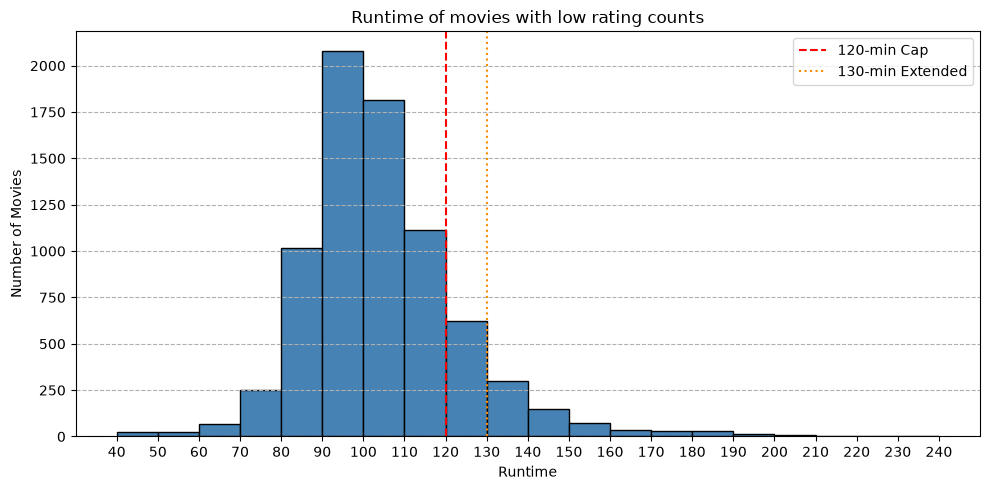

In [65]:
bins = np.arange(40, 250, 10)
low_in_range = low_reviews[(low_reviews["runtime"] >= 40) & (low_reviews["runtime"] <= 240)]

plt.figure(figsize=(10, 5))
plt.hist(low_in_range["runtime"], bins=bins, edgecolor="black", color="steelblue")

plt.axvline(120, color="red", linestyle="--", label="120-min Cap")
plt.axvline(130, color="darkorange", linestyle=":", label="130-min Extended")

plt.xticks(bins)
plt.title(f"Runtime of movies with low rating counts")
plt.xlabel("Runtime")
plt.ylabel("Number of Movies")
plt.grid(axis="y", linestyle="--")
plt.legend()
plt.tight_layout()

plt.savefig("../outputs/lowReviewCountByRuntime.png")
plt.show()

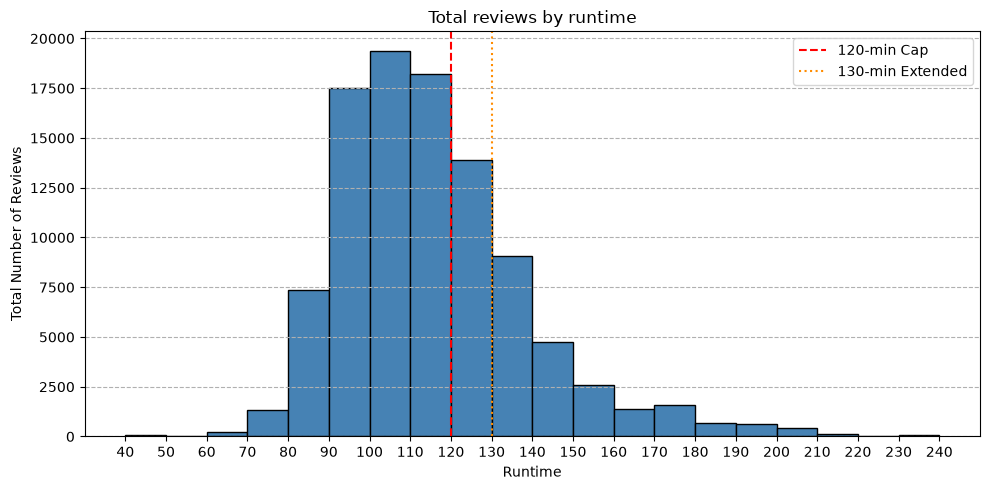

In [66]:
## histo for all movies with at least a single review.

bins = np.arange(40, 250, 10)
in_range = movie_reviews[
    (movie_reviews["runtime"] >= 40) 
    & (movie_reviews["runtime"] <= 240) 
    & (movie_reviews["rating_count"] >= 1)
]

plt.figure(figsize=(10, 5))
plt.hist(
    in_range["runtime"],
    bins=bins,
    weights=in_range["rating_count"],
    edgecolor="black",
    color="steelblue"
)

plt.axvline(120, color="red", linestyle="--", label="120-min Cap")
plt.axvline(130, color="darkorange", linestyle=":", label="130-min Extended")

plt.xticks(bins)
plt.title(f"Total reviews by runtime")
plt.xlabel("Runtime")
plt.ylabel("Total Number of Reviews")
plt.grid(axis="y", linestyle="--")
plt.legend()
plt.tight_layout()

plt.savefig("../outputs/reviews_by_runtime.png")
plt.show()


Profiling: 

In [67]:
for name, df in tables.items():
    print(f'\n{name}: {df.shape[0]:,} rows x {df.shape[1]:,} columns')
    display(df.head(3))


movies: 9,082 rows x 21 columns


,movieId,tmdbId,imdb_id,title,original_title,original_language,release_date,runtime,budget,revenue,popularity,vote_average,vote_count,genres,production_companies,production_countries,adult,status,genres_list,primary_genre,release_year
0,1,862,tt0114709,Toy Story,Toy Story,en,1995-10-30,81.0,30000000,373554033.0,21.946943,7.7,5415.0,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...","[{'name': 'Pixar Animation Studios', 'id': 3}]","[{'iso_3166_1': 'US', 'name': 'United States o...",False,Released,Animation|Comedy|Family,Animation,1995
1,2,8844,tt0113497,Jumanji,Jumanji,en,1995-12-15,104.0,65000000,262797249.0,17.015539,6.9,2413.0,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...","[{'name': 'TriStar Pictures', 'id': 559}, {'na...","[{'iso_3166_1': 'US', 'name': 'United States o...",False,Released,Adventure|Fantasy|Family,Adventure,1995
2,3,15602,tt0113228,Grumpier Old Men,Grumpier Old Men,en,1995-12-22,101.0,0,0.0,11.712900,6.5,92.0,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ...","[{'name': 'Warner Bros.', 'id': 6194}, {'name'...","[{'iso_3166_1': 'US', 'name': 'United States o...",False,Released,Romance|Comedy,Romance,1995



ratings: 99,810 rows x 5 columns


,userId,movieId,rating,timestamp,rating_datetime
0,1,31,2.5,1260759144,2009-12-14 02:52:24
1,1,1029,3.0,1260759179,2009-12-14 02:52:59
2,1,1061,3.0,1260759182,2009-12-14 02:53:02



links: 9,125 rows x 3 columns


,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0



credits: 9,082 rows x 3 columns


,tmdbId,director,top_cast
0,862,John Lasseter,Tom Hanks|Tim Allen|Don Rickles
1,8844,Joe Johnston,Robin Williams|Jonathan Hyde|Kirsten Dunst
2,15602,Howard Deutch,Walter Matthau|Jack Lemmon|Ann-Margret



keywords: 9,082 rows x 2 columns


,tmdbId,keywords_list
0,862,jealousy|toy|boy|friendship|friends|rivalry|bo...
1,8844,board game|disappearance|based on children's b...
2,15602,fishing|best friend|duringcreditsstinger|old men


In [68]:
profile_rows = []
for name, df in tables.items():
    profile_rows.append({
        'table': name,
        'rows': len(df),
        'columns': df.shape[1],
        'duplicate_rows': int(df.duplicated().sum()),
        'missing_cells': int(df.isna().sum().sum()),
    })
pd.DataFrame(profile_rows)

,table,rows,columns,duplicate_rows,missing_cells
0,movies,9082,21,0,72
1,ratings,99810,5,0,0
2,links,9125,3,0,13
3,credits,9082,3,0,114
4,keywords,9082,2,0,761


In [69]:
##Key Audit:

key_audit = pd.DataFrame([
    {"table": "movies", "expected_key": "movieId", "duplicate_keys": movies["movieId"].duplicated().sum(), "missing_key_values": movies["movieId"].isna().sum()},
    {"table": "movies", "expected_key": "tmdbId", "duplicate_keys": movies["tmdbId"].duplicated().sum(), "missing_key_values": movies["tmdbId"].isna().sum()},
    {"table": "ratings", "expected_key": "userId + movieId", "duplicate_keys": ratings[["userId", "movieId"]].duplicated().sum(), "missing_key_values": ratings[["userId", "movieId"]].isna().sum().sum()},
    {"table": "links", "expected_key": "movieId", "duplicate_keys": links["movieId"].duplicated().sum(), "missing_key_values": links["movieId"].isna().sum()},
    {"table": "credits", "expected_key": "tmdbId", "duplicate_keys": credits["tmdbId"].duplicated().sum(), "missing_key_values": credits["tmdbId"].isna().sum()},
    {"table": "keywords", "expected_key": "tmdbId", "duplicate_keys": keywords["tmdbId"].duplicated().sum(), "missing_key_values": keywords["tmdbId"].isna().sum()},
])

key_audit

,table,expected_key,duplicate_keys,missing_key_values
0,movies,movieId,0,0
1,movies,tmdbId,0,0
2,ratings,userId + movieId,0,0
3,links,movieId,0,0
4,credits,tmdbId,0,0
5,keywords,tmdbId,0,0


Further profiling:

In [70]:
display(movies.describe())

print("Minimum Budget:", int(movies["budget"].min()))
print("Maximum Budget:", int(movies["budget"].max()))
print("Median Budget:", int(movies["budget"].median()))
print("Minimum Revenue:", int(movies["revenue"].min()))
print("Maximum Revenue:", int(movies["revenue"].max()))
print("Median Revenue:", int(movies["revenue"].median()))
print()
print()

print("Missing Primary Genre Values:", movies["primary_genre"].isna().sum())
print()
print()


print("Standard Deviation Budget:", movies["budget"].std())
print("Standard Deviation Revenue:", movies["revenue"].std())







,movieId,tmdbId,runtime,budget,revenue,popularity,vote_average,vote_count,release_year
count,9082.000000,9082.000000,9082.000000,9.082000e+03,9.082000e+03,9082.000000,9082.000000,9082.000000,9082.000000
mean,30963.741577,38710.463885,105.661418,1.664789e+07,4.918728e+07,7.268905,6.362178,439.050870,1991.951993
std,40659.690679,62123.411079,30.350712,3.345276e+07,1.301801e+08,9.372314,1.038748,996.156492,19.387707
min,1.000000,2.000000,0.000000,0.000000e+00,0.000000e+00,0.000004,0.000000,0.000000,1902.000000
25%,2843.250000,9446.250000,93.000000,0.000000e+00,0.000000e+00,2.954521,5.800000,29.000000,1984.000000
50%,6265.500000,15775.000000,102.000000,1.000000e+05,2.716080e+05,6.418871,6.500000,96.000000,1997.000000
75%,56026.250000,39010.250000,115.000000,2.000000e+07,3.672528e+07,9.861742,7.000000,365.750000,2006.000000
max,163949.000000,416437.000000,1140.000000,3.800000e+08,2.787965e+09,547.488298,10.000000,14075.000000,2016.000000


Minimum Budget: 0
Maximum Budget: 380000000
Median Budget: 100000
Minimum Revenue: 0
Maximum Revenue: 2787965087
Median Revenue: 271608


Missing Primary Genre Values: 35


Standard Deviation Budget: 33452764.78137826
Standard Deviation Revenue: 130180082.2989355


In [71]:
display(movie_reviews[["runtime", "rating_count", "avg_user_rating"]].describe())


valid_rt = movie_reviews[movie_reviews["runtime"] > 0]
print("Movies with 0 or missing runtime:", (movie_reviews["runtime"].fillna(0) == 0).sum())
print("Minimum runtime:", int(valid_rt["runtime"].min()))
print("Maximum runtime:", int(valid_rt["runtime"].max()))
print("Median runtime:", int(valid_rt["runtime"].median()))
print("Standard Deviation Runtime:", round(valid_rt["runtime"].std(), 2))
print()
print()



credits_check = movie_reviews.merge(credits[["tmdbId", "director", "top_cast"]], on="tmdbId", how="left")
print("Movies missing director:", credits_check["director"].isna().sum())
print("Movies missing top cast :", credits_check["top_cast"].isna().sum())


,runtime,rating_count,avg_user_rating
count,9082.000000,9082.000000,9025.000000
mean,105.661418,10.989870,3.290203
std,30.350712,24.035568,0.881612
min,0.000000,0.000000,0.500000
25%,93.000000,1.000000,2.833333
50%,102.000000,3.000000,3.500000
75%,115.000000,9.000000,3.961538
max,1140.000000,341.000000,5.000000


Movies with 0 or missing runtime: 20
Minimum runtime: 2
Maximum runtime: 1140
Median runtime: 102
Standard Deviation Runtime: 29.98


Movies missing director: 24
Movies missing top cast : 90


Checking average runtime per genre

In [72]:
valid_rt = movie_reviews[movie_reviews["runtime"] > 0]


genre_runtime = (
    valid_rt.assign(primary_genre=valid_rt["primary_genre"].fillna("Missing"))
    .groupby("primary_genre", as_index=False)
    .agg(
        movie_count=("movieId", "count"),
        avg_runtime=("runtime", "mean"),
        median_runtime=("runtime", "median")
    )
    .sort_values("avg_runtime", ascending=False)
)

genre_runtime["avg_runtime"] = genre_runtime["avg_runtime"].round(1)
display(genre_runtime)


,primary_genre,movie_count,avg_runtime,median_runtime
9,Foreign,1,162.0,162.0
19,War,52,123.2,118.0
10,History,44,117.7,115.0
20,Western,48,117.3,119.5
6,Drama,2410,113.9,110.0
1,Adventure,517,110.7,107.0
18,Thriller,263,109.4,106.0
4,Crime,416,108.8,107.0
13,Music,81,108.3,105.0
0,Action,1175,107.5,104.0
